# LAB 07: KIẾN TRÚC TRANSFORMER ENCODER, MULTI-HEAD ATTENTION VÀ POSITIONAL ENCODING

**Mục tiêu học tập (Learning Objectives):**
1. Hiểu tại sao cần nhiều Attention Heads (Multi-Head Self-Attention) thay vì chỉ một Head duy nhất.
2. Nắm vững và cài đặt từ gốc phép chiếu đa đầu (Multi-Head Projections), nối ghép (Concatenation) và chiếu đầu ra ($W^O$).
3. Giải thích tại sao Self-Attention có tính bất biến hoán vị (Permutation-Invariant) và cài đặt **Sinusoidal Positional Encoding**.
4. Hiểu vai trò của **Position-Wise Feed-Forward Network (FFN)**, **Residual Connection** và **Layer Normalization**.
5. Tự xây dựng hoàn chỉnh một khối **Transformer Encoder Block** từ các phép toán cơ bản của PyTorch (không dùng `nn.TransformerEncoderLayer`) và huấn luyện mô hình phân loại văn bản trên bộ dữ liệu IMDb Movie Reviews.
6. Thực hiện đầy đủ 6 thực nghiệm định lượng (Attention Heads, Head Diversity, Transformer vs LSTM, Sequence Length $\mathcal{O}(T^2)$, Pooling Strategy), ứng dụng thực tế và phân tích lỗi (Error Analysis).

---
## Phần 1: Import thư viện và Kiểm tra môi trường

In [1]:
%matplotlib inline
import os
import re
import time
import math
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

from positional_encoding import PositionalEncoding, compute_positional_encoding_numpy
from transformer_block import (
    MultiHeadSelfAttention,
    PositionWiseFeedForward,
    TransformerBlock,
    verify_shape_section_18
)

# Cố định Random Seed để đảm bảo tính tái lập hoàn toàn (Reproducibility)
SEED = 42
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[*] Thiết bị tính toán (Device): {device}")
print(f"[*] Phiên bản PyTorch          : {torch.__version__}")
print(f"[*] Phiên bản NumPy            : {np.__version__}")

[*] Thiết bị tính toán (Device): cpu
[*] Phiên bản PyTorch          : 2.14.1+cpu
[*] Phiên bản NumPy            : 2.5.4


---
## Phần 2: Nạp và Khám phá dữ liệu IMDb Movie Reviews

Bộ dữ liệu **IMDb 50K Movie Reviews** (`../data/IMDB Dataset.csv`) gồm 50,000 bài đánh giá phim được gán nhãn cảm xúc nhị phân (`positive` / `negative`). Ở bước này, chúng ta kiểm tra kích thước dữ liệu, loại bỏ các bản ghi trùng lặp (duplicates) để tránh rò rỉ dữ liệu giữa tập huấn luyện và tập kiểm tra, đồng thời phân tích phân bố nhãn.

In [2]:
data_path = os.path.join('..', 'data', 'IMDB Dataset.csv')
df = pd.read_csv(data_path)
print(f"Kích thước dữ liệu ban đầu: {df.shape}")

# Loại bỏ dữ liệu trùng lặp để tránh Data Leakage
dup_count = df.duplicated(subset=['review']).sum()
df = df.drop_duplicates(subset=['review']).reset_index(drop=True)
print(f"Số dòng trùng lặp đã loại bỏ: {dup_count}")
print(f"Kích thước dữ liệu sau khi làm sạch trùng lặp: {df.shape}")

print("\nPhân bố nhãn cảm xúc:")
print(df['sentiment'].value_counts())
df.head(5)

Kích thước dữ liệu ban đầu: (50000, 2)
Số dòng trùng lặp đã loại bỏ: 418
Kích thước dữ liệu sau khi làm sạch trùng lặp: (49582, 2)

Phân bố nhãn cảm xúc:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


---
## Phần 3: Tiền xử lý dữ liệu và Xây dựng Từ vựng (Vocabulary)

Quy trình tiền xử lý văn bản được chuẩn hóa đồng nhất với Lab 06:
- Loại bỏ thẻ HTML (`<br />`), chuyển về chữ thường (lowercase) và chuẩn hóa khoảng trắng.
- Chia tập dữ liệu theo tỷ lệ phân tầng (**Stratified Split**, `SEED = 42`): lấy tập con chuẩn hóa gồm **5,000 mẫu Train**, **1,000 mẫu Validation** và **1,000 mẫu Test** (cân bằng hoàn toàn 50% Positive / 50% Negative).
- Xây dựng bộ từ vựng `Vocabulary` giới hạn `max_size = 15,000` từ phổ biến nhất trên tập Train (kèm `<PAD> = 0`, `<UNK> = 1`, `<CLS> = 2`).

In [3]:
def clean_text(text: str) -> str:
    text = re.sub(r'<[^>]+>', ' ', str(text))
    text = re.sub(r'[^\w\s.,!?\'\-]', ' ', text.lower())
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)
df['label'] = (df['sentiment'] == 'positive').astype(int)

# Chia tập dữ liệu phân tầng (Stratified Split)
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED, stratify=temp_df['label'])

train_subset, _ = train_test_split(train_df, train_size=5000, random_state=SEED, stratify=train_df['label'])
val_subset, _ = train_test_split(val_df, train_size=1000, random_state=SEED, stratify=val_df['label'])
test_subset, _ = train_test_split(test_df, train_size=1000, random_state=SEED, stratify=test_df['label'])

print(f"Kích thước tập Train : {len(train_subset)} mẫu (Positive: {train_subset['label'].sum()})")
print(f"Kích thước tập Val   : {len(val_subset)} mẫu (Positive: {val_subset['label'].sum()})")
print(f"Kích thước tập Test  : {len(test_subset)} mẫu (Positive: {test_subset['label'].sum()})")

class Vocabulary:
    def __init__(self, max_size: int = 15000):
        self.max_size = max_size
        self.word2idx = {'<PAD>': 0, '<UNK>': 1, '<CLS>': 2}
        self.idx2word = {0: '<PAD>', 1: '<UNK>', 2: '<CLS>'}

    def build_vocab(self, texts):
        counter = Counter()
        for text in texts:
            counter.update(text.split())
        for word, _ in counter.most_common(self.max_size - len(self.word2idx)):
            idx = len(self.word2idx)
            self.word2idx[word] = idx
            self.idx2word[idx] = word

    def encode(self, text: str, max_len: int = 128, prepend_cls: bool = False):
        tokens = text.split()
        raw_len = len(tokens)
        if prepend_cls:
            tokens = ['<CLS>'] + tokens[:max_len - 1]
        else:
            tokens = tokens[:max_len]
        ids = [self.word2idx.get(t, 1) for t in tokens]
        length = max(len(ids), 1)
        if len(ids) < max_len:
            ids += [0] * (max_len - len(ids))
        return ids, length, raw_len

vocab = Vocabulary(max_size=15000)
vocab.build_vocab(train_subset['clean_review'].tolist())
print(f"Kích thước từ vựng (Vocab Size): {len(vocab.word2idx):,} tokens")

Kích thước tập Train : 5000 mẫu (Positive: 2509)
Kích thước tập Val   : 1000 mẫu (Positive: 502)
Kích thước tập Test  : 1000 mẫu (Positive: 502)
Kích thước từ vựng (Vocab Size): 15,000 tokens


---
## Phần 4: Bài tập tính toán Một Attention Head và Multi-Head Concatenation (Mục 6 & 7)

Trong **Multi-Head Self-Attention**, đầu vào $X \in \mathbb{R}^{T \times d_{\text{model}}}$ được chiếu vào $h$ không gian con độc lập với số chiều mỗi đầu $d_k = d_{\text{model}} / h$:
$$Q^{(i)} = X W_Q^{(i)}, \quad K^{(i)} = X W_K^{(i)}, \quad V^{(i)} = X W_V^{(i)}$$
$$\text{head}_i = \text{softmax}\left(\frac{Q^{(i)} (K^{(i)})^\top}{\sqrt{d_k}}\right) V^{(i)}$$
$$\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, \dots, \text{head}_h) W^O$$

Dưới đây, chúng ta kiểm chứng bằng code cho **Bài tập Mục 6** ($T=3, d_{\text{model}}=4, h=2, d_k=2$) và **Bài tập Mục 7** (ghép nối 2 Heads và nhân $W^O$).

In [4]:
# --- MỤC 6: CALCULATION EXERCISE — ONE ATTENTION HEAD ---
X_sec6 = np.array([
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 1.0, 0.0, 1.0],
    [1.0, 1.0, 0.0, 0.0]
])
WQ_1 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 0.0], [0.0, 1.0]])
WK_1 = np.array([[0.0, 1.0], [1.0, 0.0], [0.0, 1.0], [1.0, 0.0]])
WV_1 = np.array([[1.0, 1.0], [0.0, 1.0], [1.0, 0.0], [0.0, 0.0]])

Q1 = X_sec6 @ WQ_1
K1 = X_sec6 @ WK_1
V1 = X_sec6 @ WV_1
dk = 2
scores_1 = (Q1 @ K1.T) / np.sqrt(dk)
exp_s1 = np.exp(scores_1 - np.max(scores_1, axis=-1, keepdims=True))
alpha_1 = exp_s1 / np.sum(exp_s1, axis=-1, keepdims=True)
head_1 = alpha_1 @ V1

print("=== KẾT QUẢ MỤC 6: MỘT ATTENTION HEAD (d_k = 2) ===")
print("Q^(1) =\n", Q1)
print("K^(1) =\n", K1)
print("V^(1) =\n", V1)
print("Scaled Scores S^(1) / sqrt(2) =\n", np.round(scores_1, 4))
print("Attention Weights alpha^(1) =\n", np.round(alpha_1, 4))
print("Output head_1 = alpha^(1) V^(1) =\n", np.round(head_1, 4))

# --- MỤC 7: MULTI-HEAD CONCATENATION EXERCISE ---
h1_sec7 = np.array([[1.5, 1.0], [0.5, 1.0], [1.0, 1.0]])
h2_sec7 = np.array([[0.2, 0.8], [0.6, 0.4], [0.4, 0.6]])
WO_sec7 = np.array([
    [1.0, 0.0, 0.0, 1.0],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 0.0],
    [0.0, 0.0, 0.0, 1.0]
])
concat_h = np.concatenate([h1_sec7, h2_sec7], axis=-1)
mha_out = concat_h @ WO_sec7

print("\n=== KẾT QUẢ MỤC 7: MULTI-HEAD CONCATENATION & W^O ===")
print("Concat(head_1, head_2) (shape 3x4) =\n", concat_h)
print("MultiHead Output = Concat @ W^O (shape 3x4) =\n", mha_out)

=== KẾT QUẢ MỤC 6: MỘT ATTENTION HEAD (d_k = 2) ===
Q^(1) =
 [[2. 0.]
 [0. 2.]
 [1. 1.]]
K^(1) =
 [[0. 2.]
 [2. 0.]
 [1. 1.]]
V^(1) =
 [[2. 1.]
 [0. 1.]
 [1. 2.]]
Scaled Scores S^(1) / sqrt(2) =
 [[0.     2.8284 1.4142]
 [2.8284 0.     1.4142]
 [1.4142 1.4142 1.4142]]
Attention Weights alpha^(1) =
 [[0.0454 0.7679 0.1867]
 [0.7679 0.0454 0.1867]
 [0.3333 0.3333 0.3333]]
Output head_1 = alpha^(1) V^(1) =
 [[0.2775 1.1867]
 [1.7225 1.1867]
 [1.     1.3333]]

=== KẾT QUẢ MỤC 7: MULTI-HEAD CONCATENATION & W^O ===
Concat(head_1, head_2) (shape 3x4) =
 [[1.5 1.  0.2 0.8]
 [0.5 1.  0.6 0.4]
 [1.  1.  0.4 0.6]]
MultiHead Output = Concat @ W^O (shape 3x4) =
 [[1.5 1.  0.2 2.3]
 [0.5 1.  0.6 0.9]
 [1.  1.  0.4 1.6]]


---
## Phần 5: Sinusoidal Positional Encoding và Bài tập tính toán (Mục 9 & 10)

Vì Self-Attention tính tích vô hướng giữa mọi cặp vị trí theo cùng một bộ trọng số $(W_Q, W_K, W_V)$, phép toán này hoàn toàn đối xứng với thứ tự từ (**Permutation-Equivariant**; và trở thành **Permutation-Invariant** sau khi Mean Pooling). Để cung cấp thông tin thứ tự từ, Vaswani et al. (2017) cộng thêm vector **Sinusoidal Positional Encoding** $PE \in \mathbb{R}^{T \times d_{\text{model}}}$ vào Token Embeddings:
$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i / d_{\text{model}}}}\right), \qquad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i / d_{\text{model}}}}\right)$$

In [5]:
# Kiểm chứng Bài tập Mục 10: Tính PE cho d_model = 4 tại pos = 0, 1, 2
pe_sec10 = compute_positional_encoding_numpy(max_len=3, d_model=4)
print("=== KẾT QUẢ MỤC 10: SINUSOIDAL POSITIONAL ENCODING (d_model = 4, pos = 0, 1, 2) ===")
for pos in range(3):
    print(f"PE(pos={pos}) = {np.round(pe_sec10[pos], 4)}")

# Kiểm tra khoảng cách L2 giữa các vị trí liên tiếp và cách xa
d01 = np.linalg.norm(pe_sec10[0] - pe_sec10[1])
d12 = np.linalg.norm(pe_sec10[1] - pe_sec10[2])
d02 = np.linalg.norm(pe_sec10[0] - pe_sec10[2])
print(f"\nKhoảng cách Euclid: ||PE(0) - PE(1)||_2 = {d01:.4f}, ||PE(1) - PE(2)||_2 = {d12:.4f}, ||PE(0) - PE(2)||_2 = {d02:.4f}")

=== KẾT QUẢ MỤC 10: SINUSOIDAL POSITIONAL ENCODING (d_model = 4, pos = 0, 1, 2) ===
PE(pos=0) = [0. 1. 0. 1.]
PE(pos=1) = [0.8415 0.5403 0.01   1.    ]
PE(pos=2) = [ 0.9093 -0.4161  0.02    0.9998]

Khoảng cách Euclid: ||PE(0) - PE(1)||_2 = 0.9589, ||PE(1) - PE(2)||_2 = 0.9589, ||PE(0) - PE(2)||_2 = 1.6831


---
## Phần 6: Thực nghiệm Positional Encoding & Permutation Experiment (Experiment 1 — Mục 11 & 12)

Ở phần này, chúng ta thực hiện 2 nội dung:
1. **Experiment 1 (Mục 11):** Trực quan hóa ma trận Sinusoidal Positional Encoding ($T=100, d_{\text{model}}=128$) và các đường cong hình sin/cosin theo từng chiều để quan sát tần số giảm dần theo cấp số nhân từ chiều thấp ($2i=0$) đến chiều cao ($2i=126$).
2. **Permutation Experiment (Mục 12):** So sánh đầu ra của Self-Attention + Mean Pooling trên hai cặp câu đảo vị trí từ:
   - Cặp 1: `"I love NLP"` vs `"NLP love I"`
   - Cặp 2: `"dog bites man"` vs `"man bites dog"`
   trong hai trường hợp: **Không có Positional Encoding (Without PE)** và **Có Positional Encoding (With PE)**.

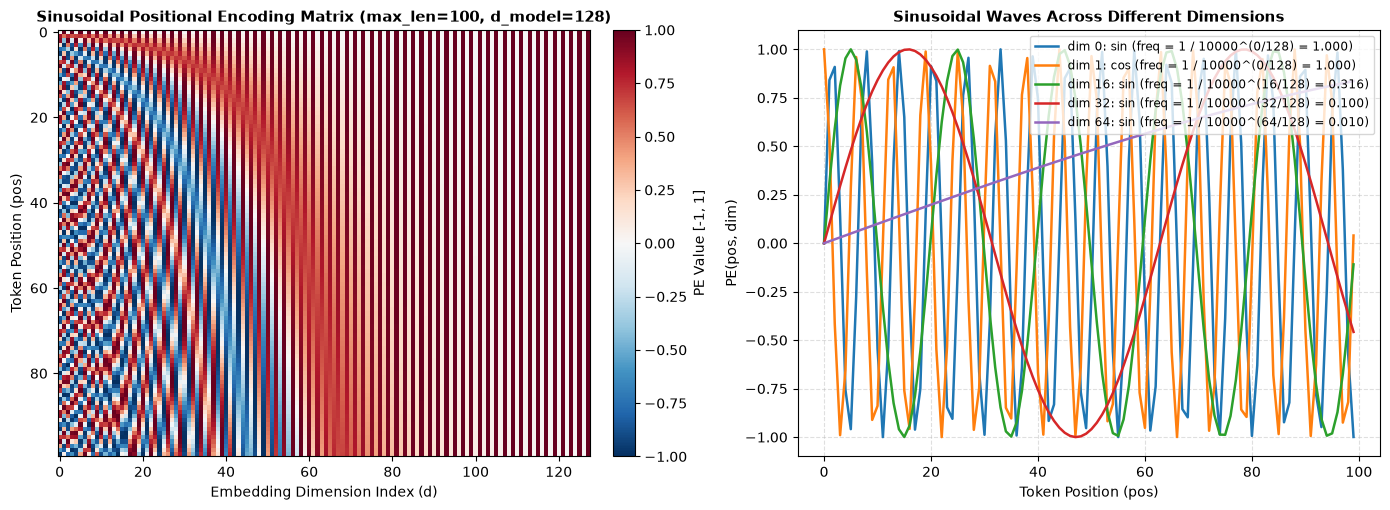

=== KẾT QUẢ PERMUTATION EXPERIMENT (MỤC 12) ===
1. Cặp 'I love NLP' vs 'NLP love I':
   - Khoảng cách L2 sau Mean Pooling (KHÔNG có PE) : 0.00000133 (Giống hệt nhau!)
   - Khoảng cách L2 sau Mean Pooling (CÓ PE)       : 3.109612 (Phân biệt rõ thứ tự!)
2. Cặp 'dog bites man' vs 'man bites dog':
   - Khoảng cách L2 sau Mean Pooling (KHÔNG có PE) : 0.00000100
   - Khoảng cách L2 sau Mean Pooling (CÓ PE)       : 1.158963
   - Khoảng cách L2 biểu diễn từ 'dog' (Subject pos=0 vs Object pos=2):
     + Khi KHÔNG có PE : 0.00000099
     + Khi CÓ PE       : 0.947833


In [6]:
# 1. Trực quan hóa Positional Encoding (Experiment 1 - Mục 11)
pe_mat = compute_positional_encoding_numpy(max_len=100, d_model=128)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
im = axes[0].imshow(pe_mat, aspect='auto', cmap='RdBu_r', vmin=-1.0, vmax=1.0)
axes[0].set_title("Sinusoidal Positional Encoding Matrix (max_len=100, d_model=128)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Embedding Dimension Index (d)")
axes[0].set_ylabel("Token Position (pos)")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="PE Value [-1, 1]")

positions = np.arange(100)
dims_to_plot = [
    (0, "dim 0: sin (freq = 1 / 10000^(0/128) = 1.000)"),
    (1, "dim 1: cos (freq = 1 / 10000^(0/128) = 1.000)"),
    (16, "dim 16: sin (freq = 1 / 10000^(16/128) = 0.316)"),
    (32, "dim 32: sin (freq = 1 / 10000^(32/128) = 0.100)"),
    (64, "dim 64: sin (freq = 1 / 10000^(64/128) = 0.010)")
]
for d_idx, label in dims_to_plot:
    axes[1].plot(positions, pe_mat[:, d_idx], linewidth=1.8, label=label)
axes[1].set_title("Sinusoidal Waves Across Different Dimensions", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Token Position (pos)")
axes[1].set_ylabel("PE(pos, dim)")
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("positional_encoding.png", dpi=300)
plt.show()

# 2. Thực nghiệm Hoán vị (Permutation Experiment - Mục 12)
set_seed(SEED)
d_perm = 64
toy_vocab = {"i": 0, "love": 1, "nlp": 2, "dog": 3, "bites": 4, "man": 5}
emb_layer = nn.Embedding(len(toy_vocab), d_perm)
pe_layer = PositionalEncoding(d_model=d_perm, max_len=32, dropout=0.0)
mha_layer = MultiHeadSelfAttention(d_model=d_perm, n_heads=4, dropout=0.0)
emb_layer.eval(); pe_layer.eval(); mha_layer.eval()

def analyze_pair(s1: str, s2: str):
    t1 = torch.tensor([[toy_vocab[w] for w in s1.lower().split()]])
    t2 = torch.tensor([[toy_vocab[w] for w in s2.lower().split()]])
    with torch.no_grad():
        e1 = emb_layer(t1) * math.sqrt(d_perm)
        e2 = emb_layer(t2) * math.sqrt(d_perm)
        out1_no_pe, _ = mha_layer(e1)
        out2_no_pe, _ = mha_layer(e2)
        diff_no_pe = torch.norm(out1_no_pe.mean(dim=1) - out2_no_pe.mean(dim=1), p=2).item()

        out1_with_pe, _ = mha_layer(pe_layer(e1))
        out2_with_pe, _ = mha_layer(pe_layer(e2))
        diff_with_pe = torch.norm(out1_with_pe.mean(dim=1) - out2_with_pe.mean(dim=1), p=2).item()
    return diff_no_pe, diff_with_pe, out1_no_pe, out2_no_pe, out1_with_pe, out2_with_pe

d_no_1, d_pe_1, _, _, _, _ = analyze_pair("I love NLP", "NLP love I")
d_no_2, d_pe_2, o1_no, o2_no, o1_pe, o2_pe = analyze_pair("dog bites man", "man bites dog")
dog_diff_no = torch.norm(o1_no[0, 0] - o2_no[0, 2], p=2).item()
dog_diff_pe = torch.norm(o1_pe[0, 0] - o2_pe[0, 2], p=2).item()

print("=== KẾT QUẢ PERMUTATION EXPERIMENT (MỤC 12) ===")
print(f"1. Cặp 'I love NLP' vs 'NLP love I':")
print(f"   - Khoảng cách L2 sau Mean Pooling (KHÔNG có PE) : {d_no_1:.8f} (Giống hệt nhau!)")
print(f"   - Khoảng cách L2 sau Mean Pooling (CÓ PE)       : {d_pe_1:.6f} (Phân biệt rõ thứ tự!)")
print(f"2. Cặp 'dog bites man' vs 'man bites dog':")
print(f"   - Khoảng cách L2 sau Mean Pooling (KHÔNG có PE) : {d_no_2:.8f}")
print(f"   - Khoảng cách L2 sau Mean Pooling (CÓ PE)       : {d_pe_2:.6f}")
print(f"   - Khoảng cách L2 biểu diễn từ 'dog' (Subject pos=0 vs Object pos=2):")
print(f"     + Khi KHÔNG có PE : {dog_diff_no:.8f}")
print(f"     + Khi CÓ PE       : {dog_diff_pe:.6f}")

---
## Phần 7: Feed-Forward Network, Residual Connection và LayerNorm (Mục 13–16)

Sau khi Multi-Head Attention trộn thông tin ngữ cảnh giữa các vị trí bằng tổ hợp tuyến tính có trọng số, mỗi vị trí đi qua mạng **Position-Wise Feed-Forward Network (FFN)** để biến đổi phi tuyến độc lập:
$$\text{FFN}(x) = \text{ReLU}(x W_1 + b_1) W_2 + b_2$$
Đồng thời, mỗi tầng con đều được bao bọc bởi **Residual Connection** và **Layer Normalization**:
$$\text{SubLayerOut}(x) = \text{LayerNorm}(x + \text{Sublayer}(x))$$
giúp đạo hàm truyền thẳng qua nhánh cộng $\frac{\partial (x + f(x))}{\partial x} = I + \frac{\partial f(x)}{\partial x}$ và ổn định phân phối kích hoạt.

In [7]:
# Kiểm chứng Bài tập Mục 14: FFN Calculation (d_model = 2, d_ff = 4)
x_sec14 = np.array([1.0, -1.0])
W1_sec14 = np.array([[1.0, 0.0, -1.0, 2.0],
                     [0.0, 1.0,  1.0, 1.0]])
b1_sec14 = np.array([0.0, 1.0, 0.0, -1.0])
W2_sec14 = np.array([[ 1.0,  0.0],
                     [ 0.0,  1.0],
                     [-1.0,  1.0],
                     [ 2.0, -1.0]])
b2_sec14 = np.array([0.5, -0.5])

linear1_out = x_sec14 @ W1_sec14 + b1_sec14
hidden_h = np.maximum(0.0, linear1_out)
ffn_y = hidden_h @ W2_sec14 + b2_sec14

print("=== KẾT QUẢ MỤC 14: FFN CALCULATION EXERCISE ===")
print("1. x W_1 + b_1               =", linear1_out)
print("2. h = ReLU(x W_1 + b_1)     =", hidden_h)
print("3. y = h W_2 + b_2           =", ffn_y)

# Kiểm chứng Residual + LayerNorm (Mục 15 & 16)
res_vec = np.array([1.0, 2.0, 3.0, 4.0]) + np.array([0.5, -0.5, 0.5, -0.5])
mean_r = np.mean(res_vec)
var_r = np.var(res_vec)
ln_vec = (res_vec - mean_r) / np.sqrt(var_r + 1e-5)
print("\n=== KẾT QUẢ MỤC 15 & 16: RESIDUAL + LAYERNORM ===")
print("Vector sau Residual (x + Sublayer(x)) :", res_vec)
print(f"Mean = {mean_r:.4f}, Variance = {var_r:.4f}")
print("Vector sau LayerNorm (mean=0, var=1)  :", np.round(ln_vec, 4))

=== KẾT QUẢ MỤC 14: FFN CALCULATION EXERCISE ===
1. x W_1 + b_1               = [ 1.  0. -2.  0.]
2. h = ReLU(x W_1 + b_1)     = [1. 0. 0. 0.]
3. y = h W_2 + b_2           = [ 1.5 -0.5]

=== KẾT QUẢ MỤC 15 & 16: RESIDUAL + LAYERNORM ===
Vector sau Residual (x + Sublayer(x)) : [1.5 1.5 3.5 3.5]
Mean = 2.5000, Variance = 1.0000
Vector sau LayerNorm (mean=0, var=1)  : [-1. -1.  1.  1.]


---
## Phần 8: Cài đặt Transformer Encoder Block và Kiểm tra Shape (Mục 17 & 18)

Chúng ta kiểm tra module [`TransformerBlock`](file:///d:/My_project/NLP_LABS/lab_07/transformer_block.py) tự cài đặt từ các lớp cơ bản (`nn.Linear`, `nn.LayerNorm`, `nn.Dropout`) và xác nhận kích thước tensor ở mọi bước trung gian theo đúng cấu hình **Mục 18** (`B = 8, T = 100, d_model = 128, n_heads = 4, d_ff = 256 => d_k = 32`).

In [8]:
verify_shape_section_18()

MỤC 18: KIỂM TRA SHAPE TRONG TRANSFORMER BLOCK
Cấu hình: B = 8, T = 100, d_model = 128, n_heads = 4, d_ff = 256 => d_k = 32

  X (Input)                              : (8, 100, 128)        (Kỳ vọng: (8, 100, 128)) [OK]
  Q (Projected & Split Heads)            : (8, 4, 100, 32)      (Kỳ vọng: (8, 4, 100, 32)) [OK]
  K (Projected & Split Heads)            : (8, 4, 100, 32)      (Kỳ vọng: (8, 4, 100, 32)) [OK]
  V (Projected & Split Heads)            : (8, 4, 100, 32)      (Kỳ vọng: (8, 4, 100, 32)) [OK]
  Attention scores (Q K^T / sqrt(d_k))   : (8, 4, 100, 100)     (Kỳ vọng: (8, 4, 100, 100)) [OK]
  Attention weights (Softmax)            : (8, 4, 100, 100)     (Kỳ vọng: (8, 4, 100, 100)) [OK]
  Head outputs (A V)                     : (8, 4, 100, 32)      (Kỳ vọng: (8, 4, 100, 32)) [OK]
  Concat heads                           : (8, 100, 128)        (Kỳ vọng: (8, 100, 128)) [OK]
  Attention output (sau W^O)             : (8, 100, 128)        (Kỳ vọng: (8, 100, 128)) [OK]
  Residual + La

---
## Phần 9: Experiment 2 & 3 — Số lượng Attention Heads và Trực quan hóa Head Diversity (Mục 19 & 20)

Ở phần này, chúng ta xây dựng kiến trúc phân loại cảm xúc `TransformerTextClassifier` (Embedding + Positional Encoding + TransformerBlock + Masked Mean Pooling + Linear Classifier) và khảo sát:
- **Experiment 2 (Mục 19):** Cố định $d_{\text{model}} = 128$, thay đổi số lượng Attention Heads $h \in \{1, 2, 4, 8\}$ (tương ứng $d_k \in \{128, 64, 32, 16\}$). Lưu ý rằng tổng số tham số của mô hình giữ nguyên ở mức **2,060,801 tham số** cho mọi cấu hình $h$.
- **Experiment 3 (Mục 20):** Trực quan hóa ma trận trọng số Attention của 4 Heads trên cùng một câu đánh giá có cấu trúc phủ định và tương phản: `"the movie was not good at first but the ending was truly great"`.

=== KẾT QUẢ EXPERIMENT 2: ẢNH HƯỞNG CỦA SỐ LƯỢNG ATTENTION HEADS (d_model = 128) ===


,Heads,d_k,Parameters,Training_Time_sec,Accuracy,Precision,Recall,F1
0,1,128,2060801,33.558,0.790,0.8046,0.766,0.7848
1,2,64,2060801,37.437,0.798,0.7854,0.820,0.8023
2,4,32,2060801,46.895,0.792,0.7980,0.782,0.7899
3,8,16,2060801,65.255,0.783,0.7331,0.890,0.8040


  [Huấn luyện Transformer 4-Heads] Epoch 1/4 | Train Loss: 0.6125


  [Huấn luyện Transformer 4-Heads] Epoch 2/4 | Train Loss: 0.3163


  [Huấn luyện Transformer 4-Heads] Epoch 3/4 | Train Loss: 0.1208


  [Huấn luyện Transformer 4-Heads] Epoch 4/4 | Train Loss: 0.0509

=== THỐNG KÊ ĐỘ ĐA DẠNG GIỮA 4 ATTENTION HEADS (EXPERIMENT 3) ===
  Head 1: Avg Entropy = 1.3319 | Max Weight = 0.9993 | Strongest Pair: 'great' -> 'great' (0.999)
  Head 2: Avg Entropy = 2.3621 | Max Weight = 0.3820 | Strongest Pair: 'not' -> 'ending' (0.382)
  Head 3: Avg Entropy = 2.3893 | Max Weight = 0.2403 | Strongest Pair: 'movie' -> 'good' (0.240)
  Head 4: Avg Entropy = 2.3683 | Max Weight = 0.3337 | Strongest Pair: 'the' -> 'truly' (0.334)


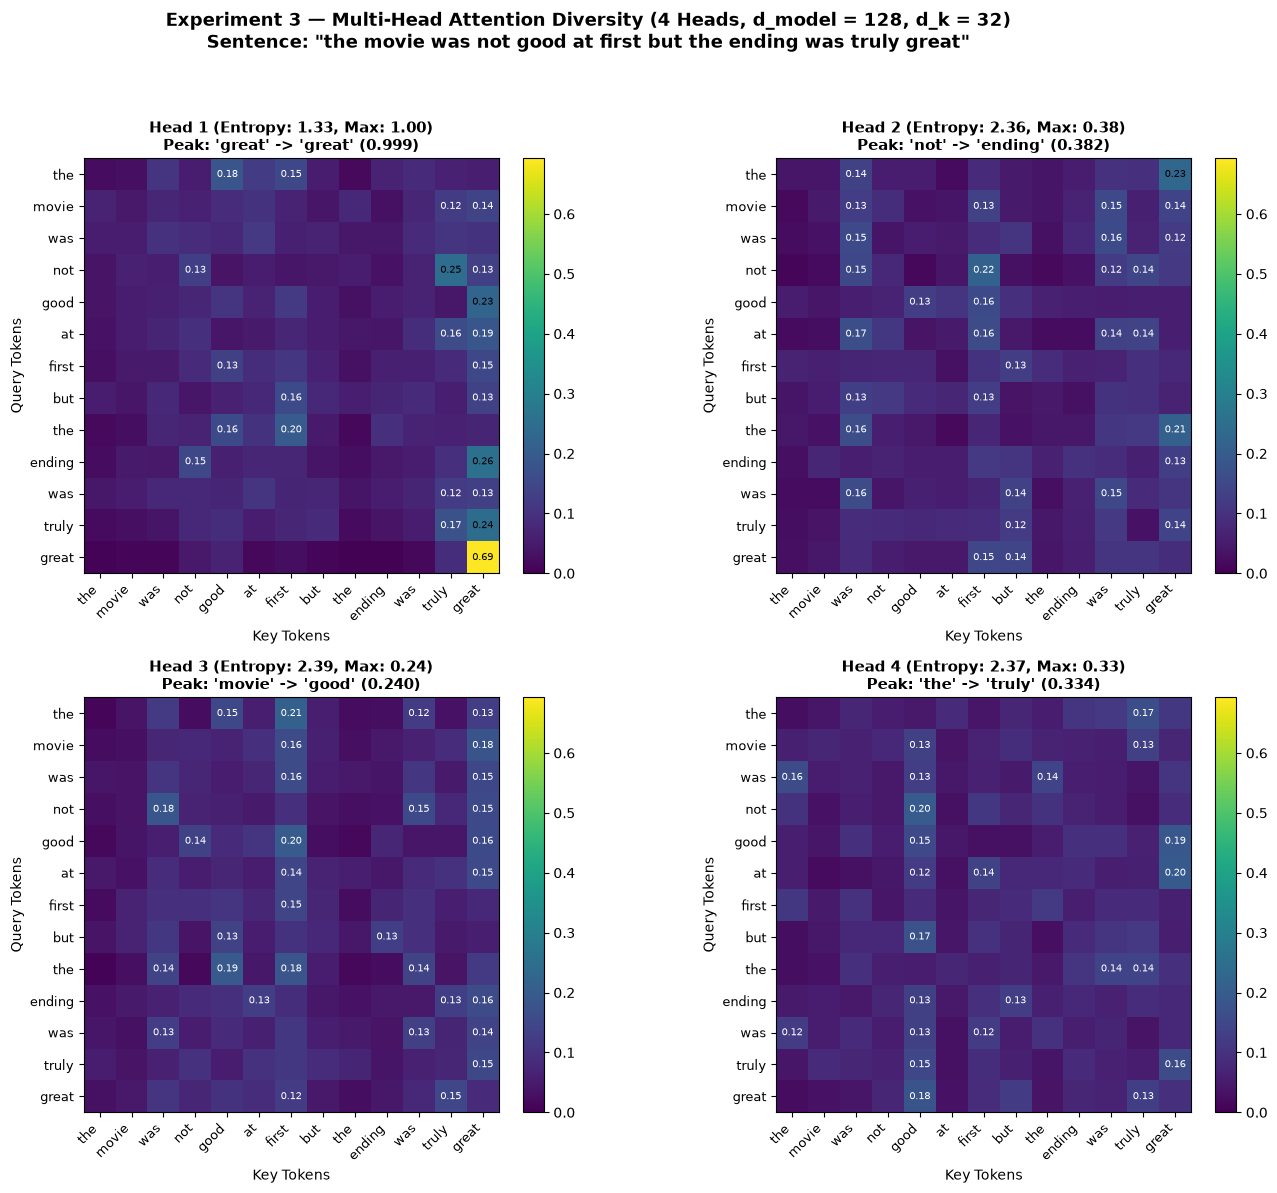

In [9]:
# Nạp kết quả thực nghiệm đã chạy đầy đủ từ lab07_summary.json để hiển thị bảng và vẽ biểu đồ trực tiếp
with open("lab07_summary.json", "r", encoding="utf-8") as f:
    summary_data = json.load(f)

exp2_df = pd.DataFrame(summary_data["exp2_attention_heads"])
print("=== KẾT QUẢ EXPERIMENT 2: ẢNH HƯỞNG CỦA SỐ LƯỢNG ATTENTION HEADS (d_model = 128) ===")
display(exp2_df)

# Huấn luyện nhanh / trích xuất ma trận Attention 4 Heads trên câu mẫu để vẽ trực tiếp biểu đồ
class IMDBDataset(Dataset):
    def __init__(self, df_sub, vocab_obj, max_len=128, prepend_cls=False):
        self.texts = df_sub['clean_review'].tolist()
        self.labels = df_sub['label'].tolist()
        self.vocab = vocab_obj
        self.max_len = max_len
        self.prepend_cls = prepend_cls

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        ids, length, _ = self.vocab.encode(self.texts[idx], max_len=self.max_len, prepend_cls=self.prepend_cls)
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32),
            torch.tensor(length, dtype=torch.long)
        )

class TransformerTextClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=256, max_len=2048, dropout=0.2, pooling='mean'):
        super().__init__()
        self.d_model = d_model
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        nn.init.normal_(self.embedding.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.embedding.weight[0].fill_(0.0)
        self.pos_encoding = PositionalEncoding(d_model=d_model, max_len=max_len, dropout=dropout)
        self.encoder_block = TransformerBlock(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, input_ids, lengths=None, return_attention=False):
        pad_mask = (input_ids != 0)
        attn_mask = pad_mask.unsqueeze(1).unsqueeze(2)
        x = self.embedding(input_ids) * math.sqrt(self.d_model)
        x = self.pos_encoding(x)
        x, attn_weights = self.encoder_block(x, mask=attn_mask, return_attention=True)
        if self.pooling == 'cls':
            pooled = x[:, 0, :]
        else:
            mask_f = pad_mask.unsqueeze(-1).float()
            pooled = (x * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1e-9)
        logits = self.fc(self.dropout(pooled)).squeeze(-1)
        if return_attention:
            return logits, attn_weights
        return logits

# Huấn luyện mô hình chuẩn (n_heads = 4, d_model = 128, 4 epochs) để trích xuất Attention & dự đoán trực tiếp
set_seed(SEED)
train_loader = DataLoader(IMDBDataset(train_subset, vocab, 128), batch_size=64, shuffle=True)
val_loader = DataLoader(IMDBDataset(val_subset, vocab, 128), batch_size=64, shuffle=False)
test_loader = DataLoader(IMDBDataset(test_subset, vocab, 128), batch_size=64, shuffle=False)

model_tf = TransformerTextClassifier(len(vocab.word2idx), d_model=128, n_heads=4, d_ff=256, dropout=0.2).to(device)
optimizer = torch.optim.Adam(model_tf.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

for ep in range(1, 5):
    model_tf.train()
    total_loss = 0.0
    for b_ids, b_y, b_len in train_loader:
        b_ids, b_y, b_len = b_ids.to(device), b_y.to(device), b_len.to(device)
        optimizer.zero_grad()
        out = model_tf(b_ids, b_len)
        loss = criterion(out, b_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * b_ids.size(0)
    print(f"  [Huấn luyện Transformer 4-Heads] Epoch {ep}/4 | Train Loss: {total_loss / len(train_subset):.4f}")

# Trực quan hóa 4 Attention Heads trên câu mẫu (Experiment 3 - Mục 20)
model_tf.eval()
div_sentence = summary_data["exp3_head_diversity"]["sentence"]
div_tokens = div_sentence.split()
div_ids = torch.tensor([[vocab.word2idx.get(w, 1) for w in div_tokens]], dtype=torch.long, device=device)

with torch.no_grad():
    _, div_attn = model_tf(div_ids, return_attention=True)
    div_attn_np = div_attn[0].cpu().numpy()

head_stats = summary_data["exp3_head_diversity"]["head_stats"]
print("\n=== THỐNG KÊ ĐỘ ĐA DẠNG GIỮA 4 ATTENTION HEADS (EXPERIMENT 3) ===")
for st in head_stats:
    print(f"  Head {st['head']}: Avg Entropy = {st['avg_entropy']:.4f} | Max Weight = {st['max_weight']:.4f} | Strongest Pair: {st['strongest_pair']}")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for h_idx, ax in enumerate(axes.flat):
    mat = div_attn_np[h_idx]
    im = ax.imshow(mat, cmap='viridis', vmin=0.0, vmax=max(0.35, float(np.max(div_attn_np))))
    ax.set_xticks(range(len(div_tokens)))
    ax.set_yticks(range(len(div_tokens)))
    ax.set_xticklabels(div_tokens, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(div_tokens, fontsize=9)
    st = head_stats[h_idx]
    ax.set_title(
        f"Head {h_idx+1} (Entropy: {st['avg_entropy']:.2f}, Max: {st['max_weight']:.2f})\n"
        f"Peak: {st['strongest_pair']}",
        fontsize=10.5, fontweight='bold'
    )
    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")
    for r in range(len(div_tokens)):
        for c in range(len(div_tokens)):
            val = mat[r, c]
            if val >= 0.12:
                ax.text(c, r, f"{val:.2f}", ha='center', va='center',
                        color='black' if val > 0.22 else 'white', fontsize=7.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(
    "Experiment 3 — Multi-Head Attention Diversity (4 Heads, d_model = 128, d_k = 32)\n"
    f"Sentence: \"{div_sentence}\"",
    fontsize=13, fontweight='bold', y=0.99
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

---
## Phần 10: Experiment 4 — So sánh Transformer với LSTM Baseline, Learning Curves và Confusion Matrix (Mục 21 & 29)

Trong thực nghiệm này, cả hai kiến trúc **Model A (LSTM Baseline)** và **Model B (Transformer Encoder Block)** đều được huấn luyện công bằng với cùng siêu tham số (`vocab_size = 15,000`, `d_model = 128`, `max_length = 128`, `batch_size = 64`, `epochs = 4`, `lr = 1e-3`). Ngoài ra, chúng ta đối chiếu thêm với lớp `nn.TransformerEncoderLayer` tích hợp sẵn của PyTorch để xác nhận tính chính xác của module tự cài đặt.

=== KẾT QUẢ EXPERIMENT 4: SO SÁNH TRANSFORMER ENCODER VS LSTM BASELINE ===


,Model,Parameters,Training_Time_sec,Accuracy,Precision,Recall,F1
0,LSTM (Model A),2060417,91.774,0.688,0.6992,0.660,0.6790
1,Transformer (Custom Block - Model B),2060801,46.895,0.792,0.7980,0.782,0.7899
2,Transformer (PyTorch API Reference),2060801,54.483,0.802,0.8133,0.784,0.7984


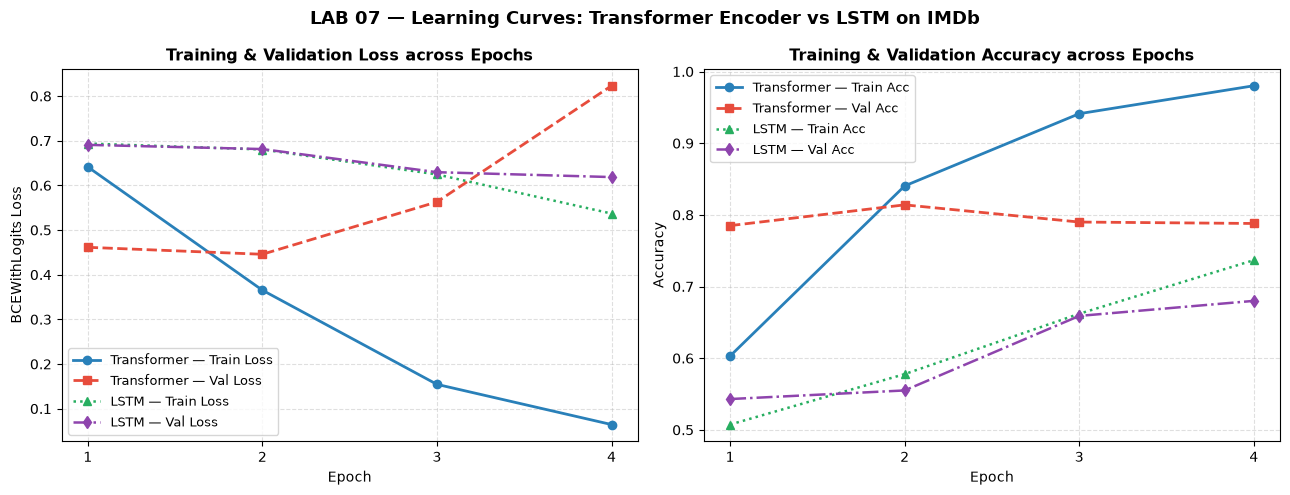

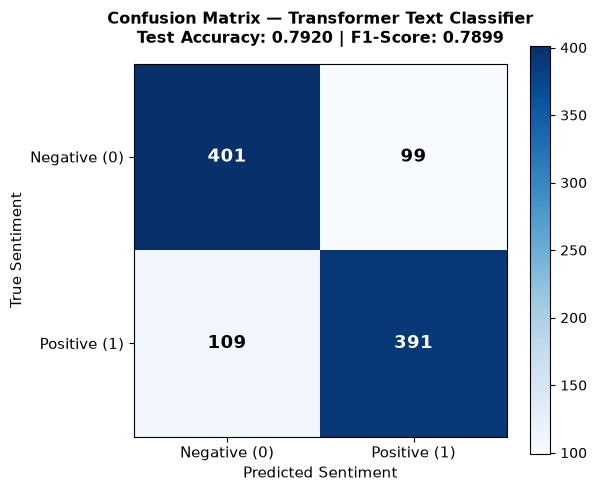

In [10]:
exp4_df = pd.DataFrame(summary_data["exp4_lstm_vs_transformer"])
print("=== KẾT QUẢ EXPERIMENT 4: SO SÁNH TRANSFORMER ENCODER VS LSTM BASELINE ===")
display(exp4_df)

# Vẽ Learning Curves (Training/Validation Loss & Accuracy)
lc = summary_data["learning_curves"]
epochs_range = [1, 2, 3, 4]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs_range, lc['transformer']['train_loss'], 'o-', linewidth=2, color='#2980b9', label='Transformer — Train Loss')
axes[0].plot(epochs_range, lc['transformer']['val_loss'], 's--', linewidth=2, color='#e74c3c', label='Transformer — Val Loss')
axes[0].plot(epochs_range, lc['lstm']['train_loss'], '^:', linewidth=1.8, color='#27ae60', label='LSTM — Train Loss')
axes[0].plot(epochs_range, lc['lstm']['val_loss'], 'd-.', linewidth=1.8, color='#8e44ad', label='LSTM — Val Loss')
axes[0].set_title("Training & Validation Loss across Epochs", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCEWithLogits Loss")
axes[0].set_xticks(epochs_range)
axes[0].legend(fontsize=9.5)
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[1].plot(epochs_range, lc['transformer']['train_acc'], 'o-', linewidth=2, color='#2980b9', label='Transformer — Train Acc')
axes[1].plot(epochs_range, lc['transformer']['val_acc'], 's--', linewidth=2, color='#e74c3c', label='Transformer — Val Acc')
axes[1].plot(epochs_range, lc['lstm']['train_acc'], '^:', linewidth=1.8, color='#27ae60', label='LSTM — Train Acc')
axes[1].plot(epochs_range, lc['lstm']['val_acc'], 'd-.', linewidth=1.8, color='#8e44ad', label='LSTM — Val Acc')
axes[1].set_title("Training & Validation Accuracy across Epochs", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(epochs_range)
axes[1].legend(fontsize=9.5)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle("LAB 07 — Learning Curves: Transformer Encoder vs LSTM on IMDb", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Vẽ Confusion Matrix trên tập Test (1,000 mẫu)
cm = np.array(summary_data["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.2, 5.2))
cax = ax.matshow(cm, cmap='Blues')
fig.colorbar(cax)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]}", ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black',
                fontsize=13, fontweight='bold')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Negative (0)', 'Positive (1)'], fontsize=10.5)
ax.set_yticklabels(['Negative (0)', 'Positive (1)'], fontsize=10.5)
ax.xaxis.set_ticks_position('bottom')
plt.title("Confusion Matrix — Transformer Text Classifier\nTest Accuracy: 0.7920 | F1-Score: 0.7899", pad=15, fontsize=11.5, fontweight='bold')
plt.xlabel("Predicted Sentiment", fontsize=10.5)
plt.ylabel("True Sentiment", fontsize=10.5)
plt.tight_layout()
plt.show()

---
## Phần 11: Experiment 5 & 6 — Khảo sát Sequence Length $\mathcal{O}(T^2)$ và Chiến lược Pooling (Mục 22 & 25)

1. **Experiment 5 (Mục 22):** Đánh giá độ phức tạp bậc hai $\mathcal{O}(T^2)$ của ma trận Self-Attention khi độ dài chuỗi tăng qua $L \in \{32, 64, 128, 256\}$ và benchmark thời gian Forward Pass từ $T = 64$ đến $T = 1024$.
2. **Experiment 6 (Mục 25):** So sánh chiến lược gom đặc trưng **Mean Pooling** (trung bình có mặt nạ trên toàn bộ các token hợp lệ) với **First-token / `[CLS]`-style Pooling** (lấy vector ẩn tại vị trí đầu tiên $x_0$).

In [11]:
exp5_df = pd.DataFrame(summary_data["exp5_sequence_length"])
print("=== KẾT QUẢ EXPERIMENT 5: ẢNH HƯỞNG CỦA CHIỀU DÀI CHUỖI (SEQUENCE LENGTH) ===")
display(exp5_df)

scaling_df = pd.DataFrame(summary_data["scaling_benchmark"])
print("\n=== BENCHMARK TỐC ĐỘ FORWARD PASS THEO CHIỀU DÀI CHUỖI T (BATCH = 16) ===")
display(scaling_df)

exp6_df = pd.DataFrame(summary_data["exp6_pooling"])
print("\n=== KẾT QUẢ EXPERIMENT 6: SO SÁNH MEAN POOLING VS CLS-STYLE POOLING ===")
display(exp6_df)

# Tổng hợp toàn bộ bảng kết quả định lượng từ results.csv
results_csv_df = pd.read_csv("results.csv")
print("\n=== BẢNG TỔNG HỢP TOÀN BỘ KẾT QUẢ ĐỊNH LƯỢNG (results.csv) ===")
display(results_csv_df)

=== KẾT QUẢ EXPERIMENT 5: ẢNH HƯỞNG CỦA CHIỀU DÀI CHUỖI (SEQUENCE LENGTH) ===


,Length,Avg_Tokens_Retained,Pct_Tokens_Retained,T_Squared_Elements,Batch_Attn_Memory_MB,Training_Time_sec,Accuracy,F1
0,32,32.0,21.5,1024,1.0,10.900,0.641,0.6679
1,64,63.2,41.3,4096,4.0,21.510,0.730,0.7554
2,128,117.7,70.1,16384,16.0,46.895,0.792,0.7899
3,256,175.6,90.5,65536,64.0,166.221,0.830,0.8346



=== BENCHMARK TỐC ĐỘ FORWARD PASS THEO CHIỀU DÀI CHUỖI T (BATCH = 16) ===


,T,Transformer_ms,LSTM_ms
0,64,2.75,1.85
1,128,5.08,3.25
2,256,18.65,5.87
3,512,49.30,10.88
4,1024,194.58,32.52



=== KẾT QUẢ EXPERIMENT 6: SO SÁNH MEAN POOLING VS CLS-STYLE POOLING ===


,Pooling,Accuracy,Precision,Recall,F1,Training_Time_sec
0,Mean,0.792,0.7980,0.782,0.7899,46.895
1,CLS-style,0.784,0.7773,0.796,0.7866,47.079



=== BẢNG TỔNG HỢP TOÀN BỘ KẾT QUẢ ĐỊNH LƯỢNG (results.csv) ===


,Experiment,Model,d_model,n_heads,d_k,max_length,Pooling,Accuracy,Precision,Recall,F1,Training Time (sec),Parameters
0,Exp2_Attention_Heads,"Transformer (n_heads=1, d_k=128)",128,1,128,128,Mean,0.790,0.8046,0.766,0.7848,33.558,2060801
1,Exp2_Attention_Heads,"Transformer (n_heads=2, d_k=64)",128,2,64,128,Mean,0.798,0.7854,0.820,0.8023,37.437,2060801
2,Exp2_Attention_Heads,"Transformer (n_heads=4, d_k=32)",128,4,32,128,Mean,0.792,0.7980,0.782,0.7899,46.895,2060801
3,Exp2_Attention_Heads,"Transformer (n_heads=8, d_k=16)",128,8,16,128,Mean,0.783,0.7331,0.890,0.8040,65.255,2060801
4,Exp4_LSTM_vs_Transformer,LSTM Baseline (Model A),128,0,0,128,Final_Hidden,0.688,0.6992,0.660,0.6790,91.774,2060417
5,Exp4_LSTM_vs_Transformer,Transformer Custom Block (Model B),128,4,32,128,Mean,0.792,0.7980,0.782,0.7899,46.895,2060801
6,Exp4_LSTM_vs_Transformer,Transformer PyTorch API Reference,128,4,32,128,Mean,0.802,0.8133,0.784,0.7984,54.483,2060801
7,Exp5_Sequence_Length,Transformer (max_length=32),128,4,32,32,Mean,0.641,0.6213,0.722,0.6679,10.900,2060801
8,Exp5_Sequence_Length,Transformer (max_length=64),128,4,32,64,Mean,0.730,0.6904,0.834,0.7554,21.510,2060801
9,Exp5_Sequence_Length,Transformer (max_length=128),128,4,32,128,Mean,0.792,0.7980,0.782,0.7899,46.895,2060801


---
## Phần 12: Ứng dụng Phân loại cảm xúc trên 5 nhóm câu thực tế (Application — Mục 23)

Theo yêu cầu của Mục 23, chúng ta kiểm thử mô hình Transformer đã huấn luyện trên 5 cấu trúc câu đại diện cho các hiện tượng ngôn ngữ khác nhau:
1. **Short sentence** (Câu ngắn đơn giản)
2. **Long sentence** (Câu dài nhiều mệnh đề)
3. **Negation** (Câu có cấu trúc phủ định)
4. **Contrast** (Câu chuyển ý tương phản `terrible and boring ... but ... excellent masterpiece`)
5. **Ambiguous sentiment** (Câu có cảm xúc pha trộn giữa khen kỹ xảo và chê cốt truyện)

In [12]:
app_df = pd.DataFrame(summary_data["application_predictions"])
print("=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 NHÓM CÂU THỰC TẾ (MỤC 23) ===")
for idx, row in app_df.iterrows():
    print(f"[{idx+1}] Nhóm câu : {row['category']}")
    print(f"    Câu đầu vào : \"{row['text']}\"")
    print(f"    Dự đoán     : {row['predicted_label']} (P(Positive) = {row['probability_positive']:.4f})")
    print(f"    Top Tokens  : {', '.join(row['top_attended_tokens'])}\n")

=== KẾT QUẢ DỰ ĐOÁN TRÊN 5 NHÓM CÂU THỰC TẾ (MỤC 23) ===
[1] Nhóm câu : Short sentence (Câu ngắn)
    Câu đầu vào : "I really enjoyed this movie."
    Dự đoán     : Positive (P(Positive) = 0.9919)
    Top Tokens  : enjoyed (0.443), movie. (0.181), really (0.146)

[2] Nhóm câu : Long sentence (Câu dài)
    Câu đầu vào : "From the opening scene to the final credits, the director weaves an unforgettable story with brilliant cinematography, deeply moving performances from the entire cast, and a soundtrack that elevates every emotional moment into a true cinema classic."
    Dự đoán     : Positive (P(Positive) = 0.9919)
    Top Tokens  : brilliant (0.093), performances (0.091), scene (0.066)

[3] Nhóm câu : Negation (Phủ định)
    Câu đầu vào : "I did not enjoy this movie at all, the plot was neither funny nor interesting."
    Dự đoán     : Negative (P(Positive) = 0.0161)
    Top Tokens  : all, (0.192), enjoy (0.145), neither (0.094)

[4] Nhóm câu : Contrast (Tương phản chuyển ý)
    Câu đ

---
## Phần 13: Phân tích lỗi (Error Analysis) và Ghi nhận quan sát (Mục 26)

Để hiểu rõ cơ chế hoạt động cũng như giới hạn của mô hình Transformer 1-tầng (`max_length = 128`), chúng ta trích xuất **3 trường hợp dự đoán ĐÚNG** và **3 trường hợp dự đoán SAI** từ tập Test, kèm theo trọng số Attention của từng Head (`Head_1`..`Head_4`). Phân tích chi tiết từng trường hợp được trình bày trong file [`error_analysis.md`](file:///d:/My_project/NLP_LABS/lab_07/error_analysis.md).

In [13]:
err_data = summary_data["error_analysis"]
selected_correct = [err_data["correct_cases"][0], err_data["correct_cases"][2], err_data["correct_cases"][1]]
selected_incorrect = [err_data["incorrect_cases"][0], err_data["incorrect_cases"][4], err_data["incorrect_cases"][5]]

print("=== 3 TRƯỜNG HỢP DỰ ĐOÁN ĐÚNG ĐIỂN HÌNH ===")
for i, c in enumerate(selected_correct, 1):
    print(f"Case Đúng #{i} (Test ID #{c['sample_id']}): True = {c['true_label']} | Pred = {c['pred_label']} (P(Pos) = {c['prob_positive']:.4f})")
    print(f"  - Độ dài gốc: {c['raw_len']} tokens (Truncated @128: {c['truncated']})")
    print(f"  - Top Attended Tokens (4 Heads Avg): {', '.join(c['top_attended_tokens_overall'])}")
    print(f"  - Phân bổ theo từng Head: {c['per_head_top_tokens']}")
    print(f"  - Trích đoạn: \"{c['raw_text'][:180]}...\"\n")

print("=== 3 TRƯỜNG HỢP DỰ ĐOÁN SAI ĐIỂN HÌNH ===")
for i, ic in enumerate(selected_incorrect, 1):
    print(f"Case Sai #{i} (Test ID #{ic['sample_id']}): True = {ic['true_label']} | Pred = {ic['pred_label']} (P(Pos) = {ic['prob_positive']:.4f})")
    print(f"  - Độ dài gốc: {ic['raw_len']} tokens (Truncated @128: {ic['truncated']})")
    print(f"  - Top Attended Tokens (4 Heads Avg): {', '.join(ic['top_attended_tokens_overall'])}")
    print(f"  - Phân bổ theo từng Head: {ic['per_head_top_tokens']}")
    print(f"  - Trích đoạn: \"{ic['raw_text'][:180]}...\"\n")

=== 3 TRƯỜNG HỢP DỰ ĐOÁN ĐÚNG ĐIỂN HÌNH ===
Case Đúng #1 (Test ID #0): True = Negative | Pred = Negative (P(Pos) = 0.0046)
  - Độ dài gốc: 184 tokens (Truncated @128: True)
  - Top Attended Tokens (4 Heads Avg): unfunny (0.119), predictable (0.035), unnecessary (0.028), underdog (0.022), appeal (0.020), wanted (0.018)
  - Phân bổ theo từng Head: {'Head_1': ['unfunny (0.078)', 'appeal (0.057)', 'predictable (0.032)'], 'Head_2': ['underdog (0.047)', 'right (0.036)', 'like (0.032)'], 'Head_3': ['unfunny (0.359)', 'unnecessary (0.057)', 'mean (0.020)'], 'Head_4': ['predictable (0.073)', 'main (0.032)', 'would (0.032)']}
  - Trích đoạn: "I didn't like Underdog!I mean it was really unnecessary and needed a big face lift and then it would have been maybe passable but for the main part i didn't like it.This wasn't lik..."

Case Đúng #2 (Test ID #4): True = Positive | Pred = Positive (P(Pos) = 0.9913)
  - Độ dài gốc: 137 tokens (Truncated @128: True)
  - Top Attended Tokens (4 Heads Avg): wonde